# Telugu FastSpeech 2: TRAINING notebook (**GPU**)

**Set the runtime to GPU first** (Runtime > Change runtime type > GPU). This is the only notebook that needs a GPU.

Needs on Drive (already there): `preprocessed_Telugu.tar`, `repo_patches.diff`, `telugu_symbols.diff`, `config_Telugu/`.

| Cell | What it does | Time |
|---|---|---|
| 1 | Rebuilds the repo, config and features from Drive | a few minutes |
| 2 | Checks that a GPU is attached | seconds |
| 3 | **Smoke test**: 200 steps. Paste its output to Claude before cell 4 | a few minutes |
| 4 | **Real training**. Resumes automatically. Stop it any time | hours |
| 5 | Loss plots + checkpoint list (also usable while training) | seconds |

Keep this tab open and visible while cell 4 runs. If the runtime resets, just run cells 1, 2 and 4 again: training resumes from the newest checkpoint on Drive.

## Cell 1: setup (restores everything from Drive)

In [1]:
import os
os.chdir("/content")                       # never start a cell inside a folder that may be deleted
LANG = "Telugu"
D = "/content/drive/MyDrive/tts_project"
from google.colab import drive
drive.mount('/content/drive')
import glob, re, shutil, subprocess
!pip install -q pyworld pypinyin unidecode inflect librosa pyyaml tgt tensorboard matplotlib scikit-learn

# a real repo has a text/ folder; a stub or half-deleted folder does not
if not os.path.isdir("/content/FastSpeech2/text"):
    shutil.rmtree("/content/FastSpeech2", ignore_errors=True)
    !git clone -q https://github.com/ming024/FastSpeech2.git /content/FastSpeech2
    !cd /content/FastSpeech2 && git apply {D}/repo_patches.diff && echo "repo patches applied"
    !cd /content/FastSpeech2 && git apply {D}/telugu_symbols.diff && echo "telugu symbols applied"
    !cp -r {D}/config_Telugu /content/FastSpeech2/config/Telugu
    !cd /content/FastSpeech2/hifigan && unzip -o -q generator_universal.pth.tar.zip
P = "/content/FastSpeech2/preprocessed_data/Telugu"
if not os.path.exists(f"{P}/train.txt"):
    !mkdir -p /content/FastSpeech2/preprocessed_data
    !tar -xf {D}/preprocessed_Telugu.tar -C /content/FastSpeech2/preprocessed_data
os.chdir("/content/FastSpeech2")
for n in ["train.txt", "val.txt", "speakers.json", "stats.json"]:
    print(n, "OK" if os.path.exists(f"{P}/{n}") else "MISSING")
print("train lines:", sum(1 for _ in open(f"{P}/train.txt", encoding="utf-8")),
      "| val lines:", sum(1 for _ in open(f"{P}/val.txt", encoding="utf-8")))
print("vocoder weights:", os.path.exists("hifigan/generator_universal.pth.tar"))
!grep -nE "multi_speaker|max_seq_len|total_step|save_step|val_step|ckpt_path" config/Telugu/model.yaml config/Telugu/train.yaml

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
repo patches applied
telugu symbols applied
train.txt OK
val.txt OK
speakers.json OK
stats.json OK
train lines: 2136 | val lines: 417
vocoder weights: True
config/Telugu/model.yaml:22:multi_speaker: true
config/Telugu/model.yaml:23:max_seq_len: 1500
config/Telugu/train.yaml:2:  ckpt_path: /content/drive/MyDrive/tts_project/output/ckpt/Telugu
config/Telugu/train.yaml:21:  total_step: 30000
config/Telugu/train.yaml:24:  val_step: 1000
config/Telugu/train.yaml:25:  save_step: 2000


## Cell 2: GPU check

In [2]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    raise SystemExit("No GPU attached. Runtime > Change runtime type > GPU, then re-run cell 1.")

GPU available: True
Tesla T4


## Cell 3: smoke test (200 steps). Paste the output before running cell 4

In [3]:
# Smoke test: 200 steps incl. validation, checkpoint and audio synthesis. Writes to LOCAL disk only.
import yaml
os.chdir("/content/FastSpeech2")
c = yaml.safe_load(open("config/Telugu/train.yaml"))
c["path"].update(ckpt_path="/content/smoke/ckpt", log_path="/content/smoke/log", result_path="/content/smoke/result")
c["step"].update(total_step=200, log_step=20, synth_step=100, val_step=100, save_step=100)
yaml.safe_dump(c, open("/content/smoke_train.yaml", "w"), sort_keys=False)
!cd /content/FastSpeech2 && python train.py -p config/Telugu/preprocess.yaml -m config/Telugu/model.yaml -t /content/smoke_train.yaml > /content/smoke.log 2>&1; echo "exit code: $?"
!tr '\r' '\n' < /content/smoke.log | grep -a -E "Number of|Total Loss|Validation|Error|Traceback|error" | tail -25
print("---- last lines ----")
!tr '\r' '\n' < /content/smoke.log | tail -4
!ls -la /content/smoke/ckpt

exit code: 0
Number of FastSpeech2 Parameters: 35352897
Epoch 1: 100%|██████████| 34/34 [01:27<00:00,  1.98s/it]Step 20/200, Total Loss: 16.6066, Mel Loss: 5.0740, Mel PostNet Loss: 5.0833, Pitch Loss: 1.8737, Energy Loss: 1.9975, Duration Loss: 2.5780
Step 40/200, Total Loss: 12.9428, Mel Loss: 4.6099, Mel PostNet Loss: 4.3880, Pitch Loss: 1.5018, Energy Loss: 1.6456, Duration Loss: 0.7975
Step 60/200, Total Loss: 12.3581, Mel Loss: 4.4053, Mel PostNet Loss: 3.9616, Pitch Loss: 1.4134, Energy Loss: 1.9207, Duration Loss: 0.6571
Step 80/200, Total Loss: 11.3824, Mel Loss: 4.2432, Mel PostNet Loss: 3.7519, Pitch Loss: 1.1942, Energy Loss: 1.6296, Duration Loss: 0.5635
Step 100/200, Total Loss: 11.1564, Mel Loss: 4.3121, Mel PostNet Loss: 3.7270, Pitch Loss: 1.2451, Energy Loss: 1.4017, Duration Loss: 0.4705
Validation Step 100, Total Loss: 9.6038, Mel Loss: 4.2402, Mel PostNet Loss: 3.1687, Pitch Loss: 0.9693, Energy Loss: 0.9887, Duration Loss: 0.2369
Step 120/200, Total Loss: 10.3483,

## Cell 4: real training (GPU)

In [ ]:
# REAL TRAINING. Resumes from the newest checkpoint on Drive. Stop the cell any time; the newest checkpoint is kept.
os.chdir("/content/FastSpeech2")
steps = [int(re.findall(r"(\d+)\.pth\.tar$", p)[0]) for p in glob.glob(f"{D}/output/ckpt/{LANG}/*.pth.tar")]
last = max(steps) if steps else 0
print("resuming from step", last)
!cd /content/FastSpeech2 && python train.py --restore_step {last} -p config/Telugu/preprocess.yaml -m config/Telugu/model.yaml -t config/Telugu/train.yaml

## Cell 5: loss plots and checkpoints

In [ ]:
# Progress + loss curves from the log files on Drive (safe to run any time, even while training elsewhere)
import re, os, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
OUT = f"{D}/Results/Telugu"; os.makedirs(OUT, exist_ok=True)
NAMES = ["Total", "Mel", "Mel PostNet", "Pitch", "Energy", "Duration"]

def parse(path):
    rows = []
    if not os.path.exists(path): return np.array(rows)
    for line in open(path):
        m = re.search(r"Step\s+(\d+)", line)
        vals = [re.search(rf"(?<![A-Za-z]){n} Loss:\s*([0-9.eE+-]+)", line) for n in NAMES]
        if m and all(vals): rows.append([int(m.group(1))] + [float(v.group(1)) for v in vals])
    return np.array(rows)

def plot(rows, title, fname, smooth=0):
    if len(rows) == 0:
        print("no parsable lines for", title); return
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, n in enumerate(NAMES):
        y = rows[:, 1 + i]
        if smooth and len(y) > smooth: y = np.convolve(y, np.ones(smooth) / smooth, mode="valid"); x = rows[smooth - 1:, 0]
        else: x = rows[:, 0]
        (ax[0] if n == "Total" else ax[1]).plot(x, y, label=n)
    ax[0].set_title(title + " (total)"); ax[1].set_title(title + " (components)")
    for a in ax: a.set_xlabel("step"); a.set_ylabel("loss"); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=150); plt.close()
    print("saved", f"{OUT}/{fname}", "| points:", len(rows), "| last step:", int(rows[-1, 0]))

LOG = f"{D}/output/log/Telugu"
tr = parse(f"{LOG}/train/log.txt"); va = parse(f"{LOG}/val/log.txt")
plot(tr, "Telugu training loss", "training_loss.png", smooth=5)
plot(va, "Telugu validation loss", "validation_loss.png")
if len(va): print("best validation total loss: %.4f at step %d" % (va[:, 1].min(), va[va[:, 1].argmin(), 0]))
print("checkpoints on Drive:", sorted(int(re.findall(r"(\d+)\.pth\.tar$", p)[0]) for p in glob.glob(f"{D}/output/ckpt/Telugu/*.pth.tar")))

In [5]:
from google.colab import drive
drive.mount('/content/drive')
import re, os, glob
D = "/content/drive/MyDrive/tts_project"
NAMES = ["Total", "Mel", "Mel PostNet", "Pitch", "Energy", "Duration"]
rows = []
for line in open(f"{D}/output/log/Telugu/val/log.txt"):
    m = re.search(r"Validation Step (\d+)", line)
    vals = [re.search(rf"(?<![A-Za-z]){n} Loss:\s*([0-9.eE+-]+)", line) for n in NAMES]
    if m and all(vals): rows.append([int(m.group(1))] + [float(v.group(1)) for v in vals])
print(f"{'step':>7} {'total':>7} {'mel':>7} {'postnet':>8} {'pitch':>7} {'energy':>7} {'dur':>7}")
for r in rows: print(f"{r[0]:>7} {r[1]:>7.3f} {r[2]:>7.3f} {r[3]:>8.3f} {r[4]:>7.3f} {r[5]:>7.3f} {r[6]:>7.3f}")
if rows:
    best = min(rows, key=lambda r: r[1])
    print("\nbest validation total loss: %.4f at step %d | latest validation step: %d" % (best[1], best[0], rows[-1][0]))
    print("validations since the best:", sum(1 for r in rows if r[0] > best[0]))
print("checkpoints on Drive:", sorted(int(re.findall(r"(\d+)\.pth\.tar$", p)[0]) for p in glob.glob(f"{D}/output/ckpt/Telugu/*.pth.tar")))

Mounted at /content/drive
   step   total     mel  postnet   pitch  energy     dur
   1000   3.768   1.001    1.024   0.924   0.741   0.078
   2000   3.785   0.971    0.968   1.031   0.742   0.073
   3000   3.859   0.980    0.980   1.007   0.819   0.072
   4000   3.943   0.993    0.993   1.082   0.800   0.074
   5000   3.944   0.991    0.992   1.079   0.811   0.071
   6000   3.901   0.982    0.981   1.058   0.807   0.073
   7000   3.948   0.989    0.989   1.057   0.842   0.072
   8000   3.951   0.988    0.987   1.042   0.862   0.072
   9000   3.966   0.994    0.993   1.060   0.848   0.072
  10000   3.934   0.990    0.990   1.020   0.860   0.074
  11000   4.000   0.994    0.994   1.065   0.876   0.072
  12000   3.959   0.996    0.995   1.024   0.870   0.074
  13000   4.013   0.996    0.995   1.055   0.894   0.073
  14000   3.971   0.996    0.996   1.028   0.877   0.074
  15000   3.988   0.995    0.995   1.039   0.886   0.073
  16000   3.972   1.003    1.002   1.030   0.864   0.074
  170

In [6]:
D = "/content/drive/MyDrive/tts_project"
!grep -E "Step (2000|6000|10000|14000|18000|22000)/" {D}/output/log/Telugu/train/log.txt

Step 2000/30000, Total Loss: 2.8943, Mel Loss: 0.8669, Mel PostNet Loss: 0.8743, Pitch Loss: 0.5669, Energy Loss: 0.4991, Duration Loss: 0.0870
Step 6000/30000, Total Loss: 1.3949, Mel Loss: 0.5611, Mel PostNet Loss: 0.5619, Pitch Loss: 0.1139, Energy Loss: 0.1138, Duration Loss: 0.0443
Step 10000/30000, Total Loss: 1.1538, Mel Loss: 0.4948, Mel PostNet Loss: 0.4940, Pitch Loss: 0.0702, Energy Loss: 0.0646, Duration Loss: 0.0302
Step 14000/30000, Total Loss: 0.9178, Mel Loss: 0.4145, Mel PostNet Loss: 0.4141, Pitch Loss: 0.0389, Energy Loss: 0.0355, Duration Loss: 0.0147
Step 18000/30000, Total Loss: 0.9383, Mel Loss: 0.4231, Mel PostNet Loss: 0.4226, Pitch Loss: 0.0398, Energy Loss: 0.0354, Duration Loss: 0.0174
Step 22000/30000, Total Loss: 0.8130, Mel Loss: 0.3759, Mel PostNet Loss: 0.3755, Pitch Loss: 0.0283, Energy Loss: 0.0250, Duration Loss: 0.0084


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- checkpoint 4000, sentence T1


--- checkpoint 4000, sentence T2a


--- checkpoint 10000, sentence T1


--- checkpoint 10000, sentence T2a


--- checkpoint 22000, sentence T1


--- checkpoint 22000, sentence T2a


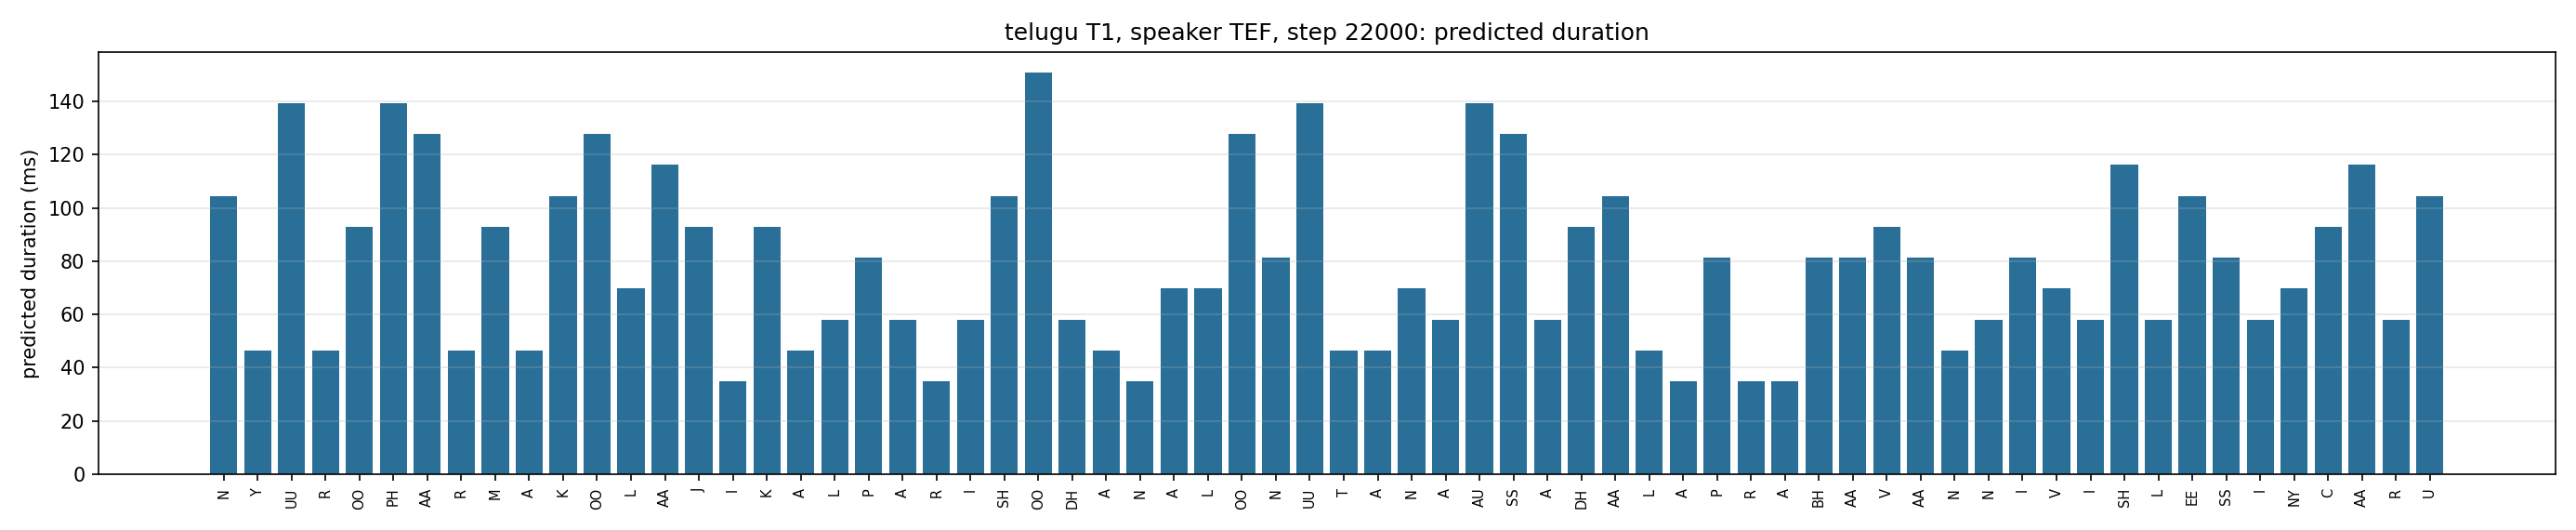

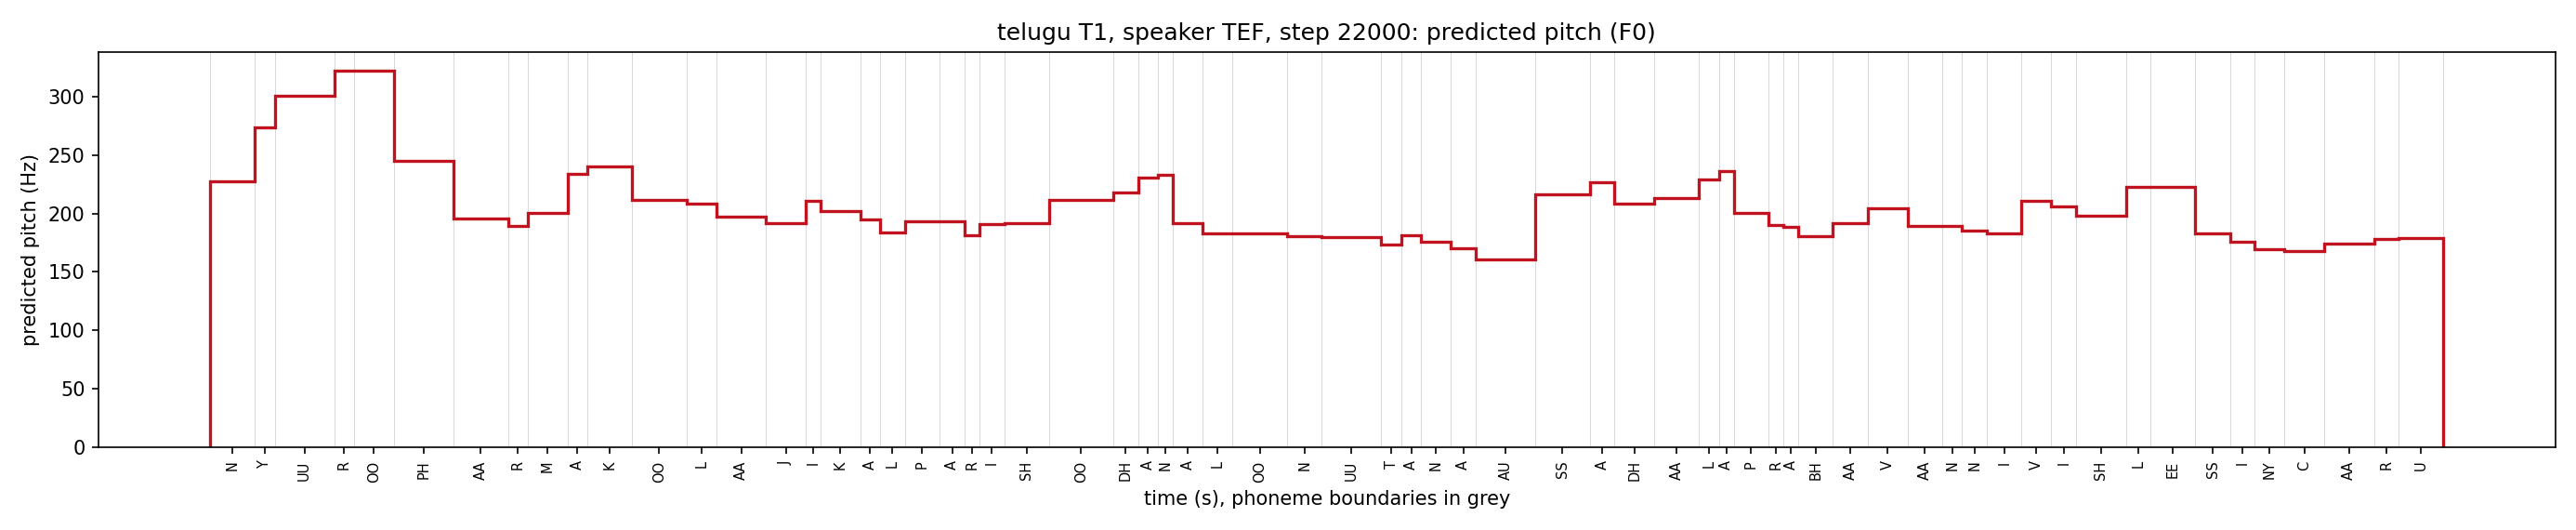

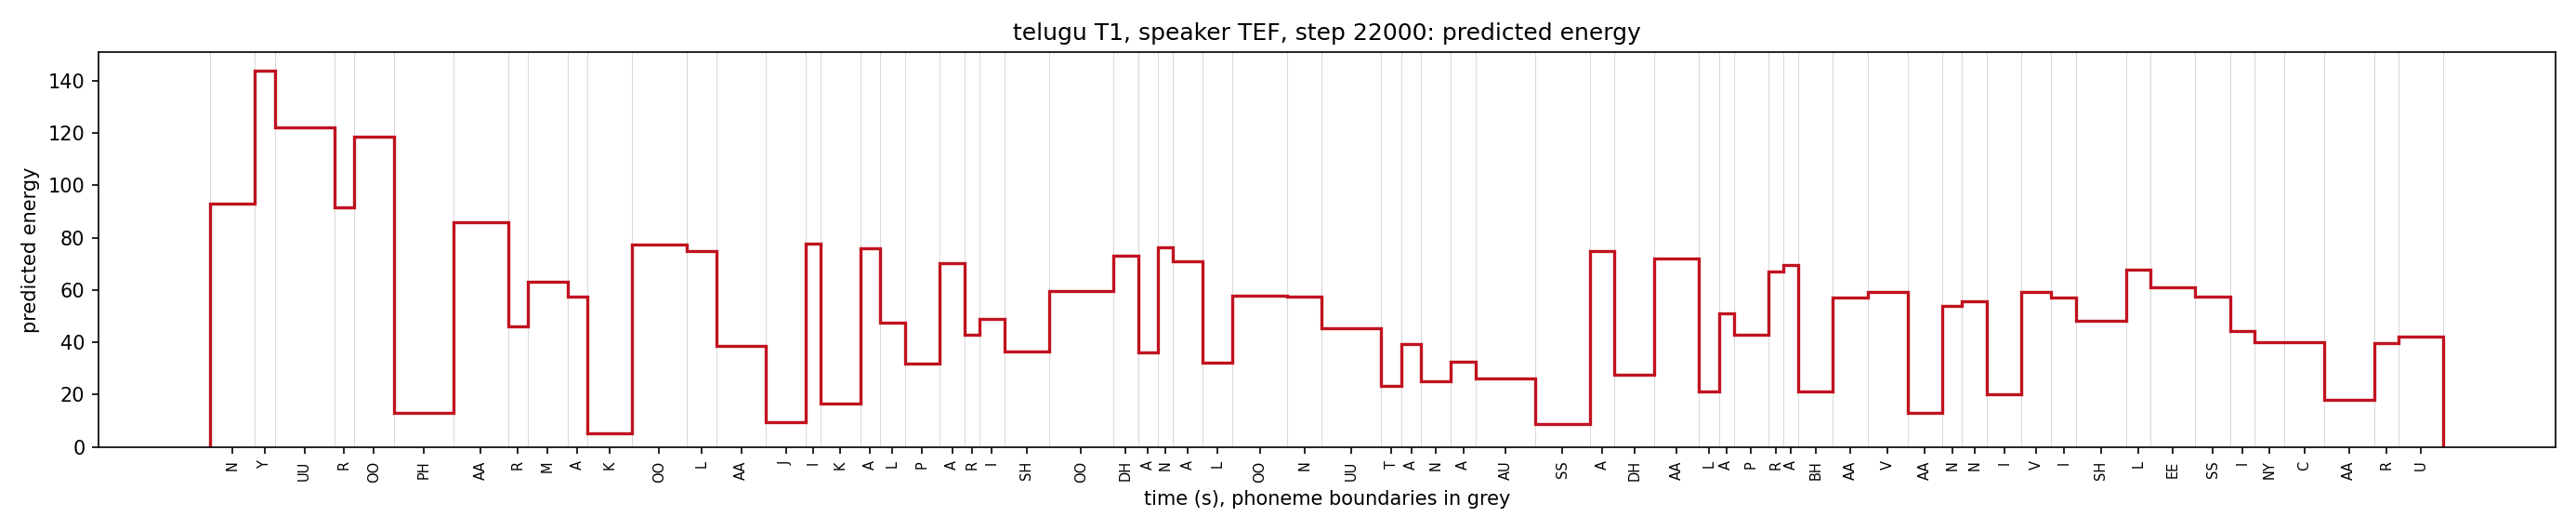

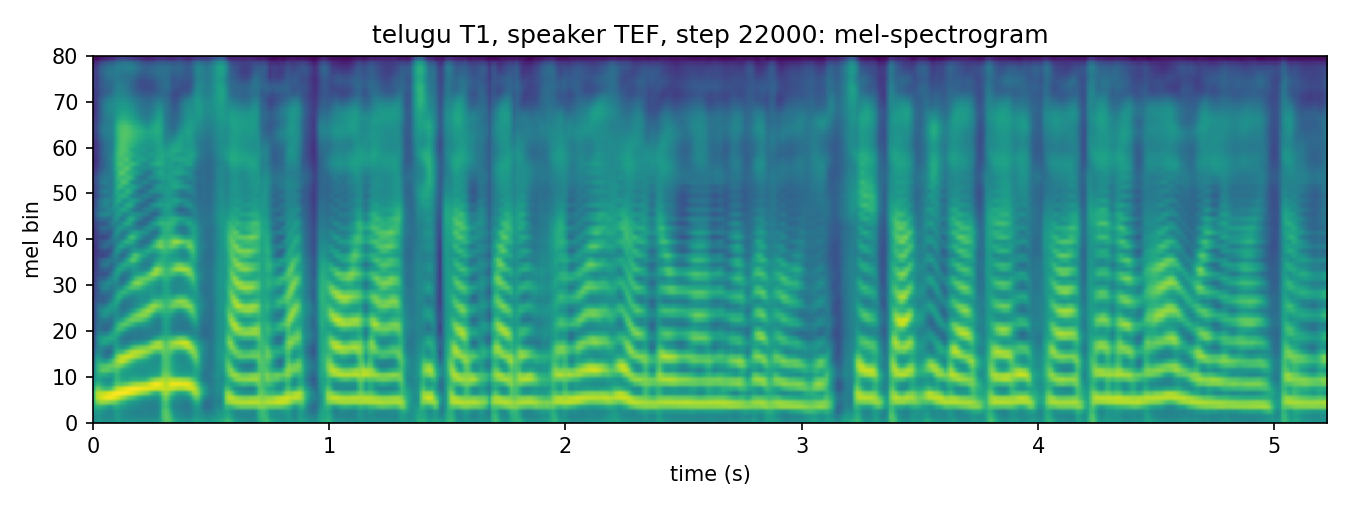

In [8]:
from google.colab import drive
drive.mount('/content/drive')
from IPython.display import Audio, Image, display
D = "/content/drive/MyDrive/tts_project"
for step in [4000, 10000, 22000]:
    for sid in ["T1", "T2a"]:
        print(f"--- checkpoint {step}, sentence {sid}")
        display(Audio(f"{D}/Results/Telugu_test/step_{step}/test_generated_audios/{sid}.wav"))
base = f"{D}/Results/Telugu_test/step_22000/variance_adaptor_plots"
for kind in ["duration", "pitch", "energy"]:
    display(Image(f"{base}/{kind}/T1.png"))
display(Image(f"{D}/Results/Telugu_test/step_22000/mel_plots/T1.png"))

In [9]:
import os
os.chdir("/content")
from google.colab import drive
drive.mount('/content/drive')
import json, shutil
D = "/content/drive/MyDrive/tts_project"
STEPS = [22000]            # which checkpoints to generate
SPEAKER = "TEF"            # TEF = female voice, TEM = male voice
OUT = f"{D}/Results/Telugu_test"

!pip install -q pyworld pypinyin unidecode inflect librosa pyyaml tgt matplotlib scikit-learn
if not os.path.isdir("/content/FastSpeech2/text"):
    shutil.rmtree("/content/FastSpeech2", ignore_errors=True)
    !git clone -q https://github.com/ming024/FastSpeech2.git /content/FastSpeech2
    !cd /content/FastSpeech2 && git apply {D}/repo_patches.diff && echo "repo patches applied"
    !cd /content/FastSpeech2 && git apply {D}/telugu_symbols.diff && echo "telugu symbols applied"
    !cp -r {D}/config_Telugu /content/FastSpeech2/config/Telugu
    !cd /content/FastSpeech2/hifigan && unzip -o -q generator_universal.pth.tar.zip
P = "/content/FastSpeech2/preprocessed_data/Telugu"
if not os.path.exists(f"{P}/stats.json"):
    !mkdir -p /content/FastSpeech2/preprocessed_data
    !tar -xf {D}/preprocessed_Telugu.tar -C /content/FastSpeech2/preprocessed_data Telugu/speakers.json Telugu/stats.json
os.chdir("/content/FastSpeech2")
assert os.path.exists(f"{D}/inference.py"), "inference.py is missing from the tts_project folder on Drive"
shutil.copy(f"{D}/inference.py", "inference.py")
sents = [
 {"id": "T1",  "text": "న్యూరోఫార్మకోలాజికల్ పరిశోధనలో నూతన ఔషధాల ప్రభావాన్ని విశ్లేషించారు."},
 {"id": "T2a", "text": "తాడుపై అతని పట్టు చాలా బలంగా ఉంది."},
 {"id": "T2b", "text": "ఆమె పట్టుచీరను ధరించి వేడుకకు వచ్చింది."},
 {"id": "T3",  "text": "పులి అడవిలో నిశ్శబ్దంగా నడిచింది."},
 {"id": "T4",  "text": "ఈ సమావేశం 2026 నవంబర్ 12వ తేదీ ఉదయం 10:45 గంటలకు ప్రారంభమవుతుంది, సమయానికి సిద్ధంగా ఉంచండి."},
]
json.dump(sents, open("test_sentences_telugu.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
for step in STEPS:
    print("=== checkpoint", step, "| speaker", SPEAKER)
    !python inference.py --lang telugu --dataset Telugu --restore_step {step} --speaker {SPEAKER} --sentences test_sentences_telugu.json --out {OUT}/step_{step}_{SPEAKER} 2>&1 | tail -8

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
repo patches applied
telugu symbols applied
=== checkpoint 22000 | speaker TEF
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
T1: 66 phones, 5.22 s of audio
T2a: 31 phones, 2.52 s of audio
T2b: 37 phones, 2.72 s of audio
T3: 31 phones, 2.25 s of audio
T4: 120 phones, 8.60 s of audio


In [10]:
import os, sys, yaml, numpy as np, torch
from scipy.io import wavfile
from IPython.display import Audio, display
from google.colab import drive
drive.mount('/content/drive')
D = "/content/drive/MyDrive/tts_project"
os.chdir("/content/FastSpeech2"); sys.path.insert(0, "/content/FastSpeech2")
!tar -xf {D}/preprocessed_Telugu.tar -C /content/FastSpeech2/preprocessed_data Telugu/mel/TEM-mel-TEM_07958.npy Telugu/mel/TEF-mel-TEF_03623.npy
!tar -xf {D}/raw_data_telugu.tar -C /content raw_data/Telugu/TEM/TEM_07958.wav raw_data/Telugu/TEF/TEF_03623.wav
from utils.model import get_vocoder, vocoder_infer
cfg = lambda n: yaml.load(open(f"config/Telugu/{n}.yaml"), Loader=yaml.FullLoader)
pre, mod = cfg("preprocess"), cfg("model")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vocoder = get_vocoder(mod, device)
out = f"{D}/Results/Telugu_test/diagnostics"; os.makedirs(out, exist_ok=True)
hop = pre["preprocessing"]["stft"]["hop_length"]; sr = pre["preprocessing"]["audio"]["sampling_rate"]
for spk, utt in [("TEM", "TEM_07958"), ("TEF", "TEF_03623")]:
    mel = np.load(f"preprocessed_data/Telugu/mel/{spk}-mel-{utt}.npy")            # (frames, 80)
    m = torch.from_numpy(mel).float().T[None].to(device)
    wav = vocoder_infer(m, vocoder, mod, pre, lengths=[mel.shape[0] * hop])[0]
    wavfile.write(f"{out}/copysynth_{utt}.wav", sr, wav)
    print(f"--- {utt}: ORIGINAL recording, then the same mel through the vocoder")
    display(Audio(f"/content/raw_data/Telugu/{spk}/{utt}.wav"))
    display(Audio(f"{out}/copysynth_{utt}.wav"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Removing weight norm...
--- TEM_07958: ORIGINAL recording, then the same mel through the vocoder


--- TEF_03623: ORIGINAL recording, then the same mel through the vocoder


In [11]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob
from IPython.display import Audio, display
D = "/content/drive/MyDrive/tts_project"
SENTENCE = "T2a"       # change to T1, T2b, T3, T4 to compare other sentences
runs = sorted(glob.glob(f"{D}/Results/Telugu_test/step_*"), key=lambda p: (len(os.path.basename(p)), p))
for r in runs:
    f = f"{r}/test_generated_audios/{SENTENCE}.wav"
    if os.path.exists(f):
        print("---", os.path.basename(r)); display(Audio(f))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- step_4000


--- step_10000


--- step_22000


--- step_22000_TEF
